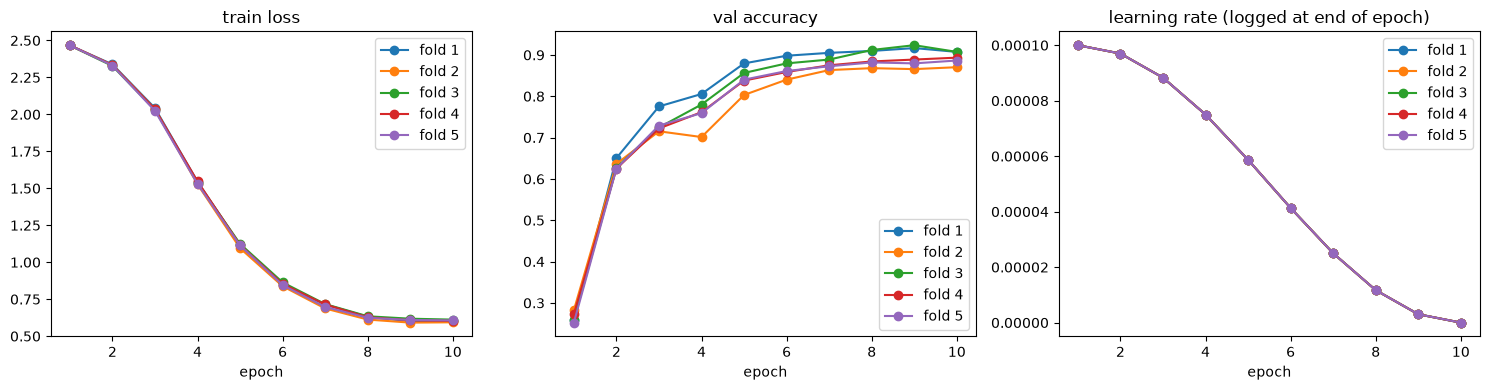

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("..") / "runs" / "baseline"   # notebook 在 notebooks/ 下，所以要往上一级
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for fold in range(1, 6):
    df = pd.read_csv(root / f"fold_{fold}" / "epochs.csv")
    axes[0].plot(df["epoch"], df["train_loss"], marker="o", label=f"fold {fold}")
    axes[1].plot(df["epoch"], df["val_accuracy"], marker="o", label=f"fold {fold}")
    axes[2].plot(df["epoch"], df["learning_rate"], marker="o", label=f"fold {fold}")

axes[0].set_title("train loss")
axes[1].set_title("val accuracy")
axes[2].set_title("learning rate (logged at end of epoch)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.savefig("../report/figures/baseline_curves.png", dpi=150)
plt.show()

你的观察大部分是对的，有两处要修正。预测的方向合理，但理由需要换一个。

## 观察：对的和要修正的

**对的**
- 五折的训练损失几乎重合。原因是每折用同一个种子、同一个预训练起点、同一条学习率曲线，训练数据又有 80% 重叠，所以轨迹接近。折与折的差异主要出现在验证准确率上，因为验证集不同，第 2 折一直偏低。
- 学习率曲线和公式吻合：第 1 轮约 1e-4，之后沿余弦下降，第 10 轮为 0。
- 前两轮上升很快：第 1 轮约 26%，第 2 轮跳到 64% 左右。第 1 轮是 warmup，所以起点低。

**要修正的两点**
1. **验证准确率没有在第 7 轮见顶。** 从图上看，7 到 9 轮之间多数折还在涨 1 到 3 个百分点，最佳 epoch 也是 9 或 10（前面表里 9、10、9、10、10）。更准确的说法是：前 6 轮快速上升，之后增速放缓，但直到结束都没有明显下降。
2. **损失"不再下降"要小心解读。** 第 7 轮损失还在掉（约 0.85 到 0.70），真正平下来是在第 8、9 轮之后，而这恰好是学习率降到接近 0 的时候。所以变平更像是**学习率耗尽**的结果，不一定是模型收敛了。

还有一个值得留意的数字：最终训练损失约 0.6。它是训练模式下带增强、整个 epoch 的平均值，不能和验证准确率直接比，但对 12 分类来说并不算小。这个图里**看不到过拟合的迹象**（过拟合通常是训练损失很低、验证准确率停滞或下降），反而更像是训练不够。这正是 E1（训练 25 个 epoch）要验证的。

## 你的预测

预测：损失降得更快，最终准确率降低，原因是过拟合。

**"准确率降低"有可能，但"过拟合"这个理由和上面的曲线不太对得上。** 基线本身没过拟合，学习率变大也不会直接造成过拟合。对预训练模型做全量微调，学习率过大更常见的问题是**步子太大，把预训练学到的特征冲坏**，同时训练也变得不稳定。另外"损失降得更快"也不一定成立，1e-3 下前期损失可能反而震荡、更高。

这两种解释可以用实验区分，看图上的特征：

| 假设 | 训练损失 | 验证准确率 |
|---|---|---|
| 过拟合（你的假设） | 很低 | 停滞或下降 |
| 破坏预训练特征 | 偏高、有波动 | 整体偏低，早期尤其明显 |

另外，因为基线的损失和准确率到最后仍有上升空间，**稍大一点的学习率（比如 3e-4）也许反而更好**。可以把 1e-3 和 3e-4 各跑一遍，你预测的是升还是降，两个都写下来。

## 现在的脚本跑不了这个实验

这个 `baseline.py` 做不了"只跑第 1 折、换学习率"，需要先改几处：

- 第 299 行：配置路径写死为 `baseline.yaml`，要加 `--config` 参数。
- 第 316 行：输出目录写死为 `runs/baseline`，且已存在会报错，要改成由实验名决定。
- 第 289、346 行：`"experiment": "baseline"` 写死，不改的话，学习率实验的结果会作为"baseline"混进 `results.csv`，把基线的记录弄乱。
- 第 322 行附近：要加 `--only-fold 1`，并且跳过 334–352 行的汇总（只有一折，OOF 检查会因为缺数据报错）。
- 第 350 行的 `write_submission` 我没看到内部，大概率会写 `submission.csv`。单折实验要跳过它，别把已有的提交文件覆盖了。

这几处改动不大，正好是你第一次真正动手改脚本的机会：自己改，或者把上面这几条交给 AI，要求"最小改动，不碰 `runs/baseline` 和 `folds.csv`"，然后对照 diff 看它改了什么。

## 你要记录的

- 基线第 1 折的最终准确率是 90.74%，这是对照值。
- 单折、单种子的差异在 1% 以内不下结论，这在前面说过。
- 写好预测再跑：1e-3 和 3e-4 各自的最终准确率，以及你预期的曲线特征。

跑完把两条曲线和基线放在一张图上发给我，我们看是过拟合、特征被冲坏，还是别的原因。